In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [4]:
df=pd.read_csv("economic_index.csv",index_col=0)
df.head()

,year,month,interest_rate,unemployment_rate,index_price
0,2017,12,2.75,5.3,1464
1,2017,11,2.50,5.3,1394
2,2017,10,2.50,5.3,1357
3,2017,9,2.50,5.3,1293
4,2017,8,2.50,5.4,1256


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               24 non-null     int64  
 1   month              24 non-null     int64  
 2   interest_rate      24 non-null     float64
 3   unemployment_rate  24 non-null     float64
 4   index_price        24 non-null     int64  
dtypes: float64(2), int64(3)
memory usage: 1.1 KB


In [6]:
# We can remove year and month
df.drop(columns=["year","month"],inplace=True)
df.head()

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256


In [ ]:
# Independent Features => Interest Rate and Unemployment Rate (2 IND FEATURES) Multiple Linear Regression
# Dependent Feature => Index Price
# Check null values
df.isnull().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

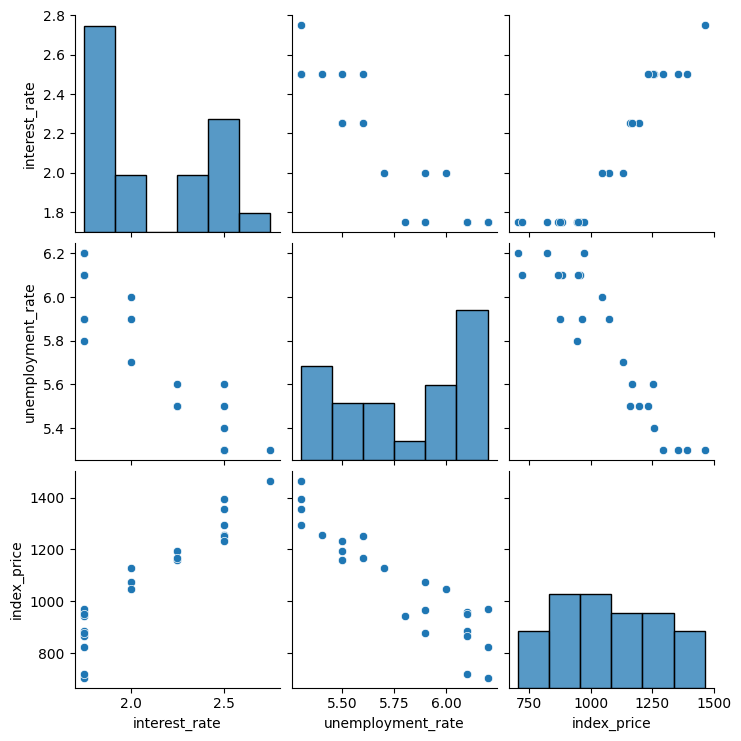

In [9]:
## Visualization
sns.pairplot(df)

In [ ]:
# Pearson Correlation
df.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


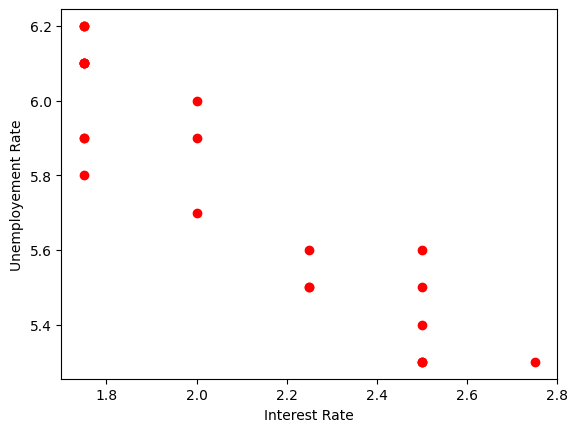

In [12]:
## Visualize the Datapoints more closely
plt.scatter(x=df["interest_rate"],y=df["unemployment_rate"],color="r")
plt.xlabel("Interest Rate")
plt.ylabel("Unemployement Rate")
plt.show()

In [14]:
# Independent and Dependent Feature
#X=df[["interest_rate","unemployment_rate"]]
X=df.iloc[:,:-1]
y=df.iloc[:,-1]

In [16]:
X.head()

,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4


In [17]:
y

0     1464
1     1394
2     1357
3     1293
4     1256
5     1254
6     1234
7     1195
8     1159
9     1167
10    1130
11    1075
12    1047
13     965
14     943
15     958
16     971
17     949
18     884
19     866
20     876
21     822
22     704
23     719
Name: index_price, dtype: int64

In [19]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

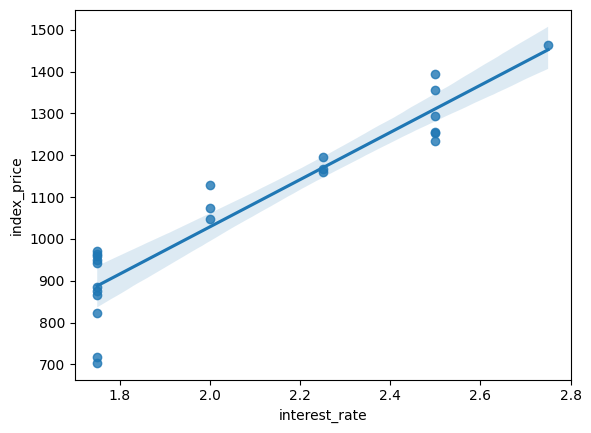

In [26]:
# New Plot in seaborn helpful to plot regression line

sns.regplot(x="interest_rate",y="index_price",data=df)
plt.show()

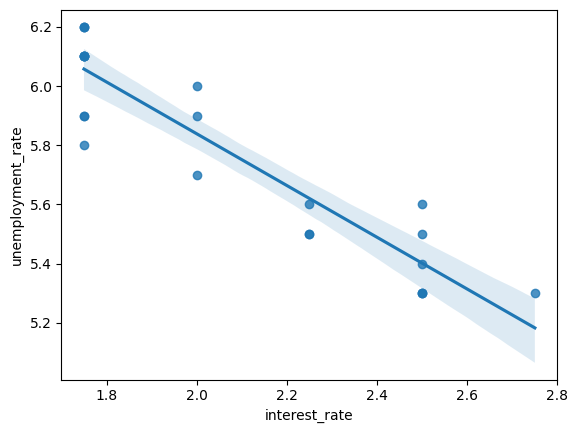

In [27]:
sns.regplot(x="interest_rate",y="unemployment_rate",data=df)
plt.show()

In [28]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [29]:
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [30]:
X_train

array([[-0.90115511,  0.37908503],
       [ 1.31077107, -1.48187786],
       [-0.90115511,  1.30956648],
       [ 1.31077107, -0.55139641],
       [ 1.31077107, -1.48187786],
       [-0.16384638,  0.68924552],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -1.48187786],
       [ 1.31077107, -1.17171738],
       [-0.90115511,  1.30956648],
       [-0.90115511,  0.999406  ],
       [-0.90115511,  0.37908503],
       [-0.90115511,  0.999406  ],
       [ 0.57346234, -0.8615569 ],
       [-0.16384638, -0.24123593],
       [-0.90115511,  0.06892455],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -0.8615569 ]])

In [31]:
from sklearn.linear_model import LinearRegression
regression=LinearRegression(n_jobs=-1)

In [32]:
regression.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",-1
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [33]:
regression.coef_,regression.intercept_

(array([  88.27275507, -116.25716066]), np.float64(1053.4444444444443))

In [35]:
X_train[:,0]

array([-0.90115511,  1.31077107, -0.90115511,  1.31077107,  1.31077107,
       -0.16384638, -0.90115511,  1.31077107,  1.31077107, -0.90115511,
       -0.90115511, -0.90115511, -0.90115511,  0.57346234, -0.16384638,
       -0.90115511, -0.90115511,  1.31077107])

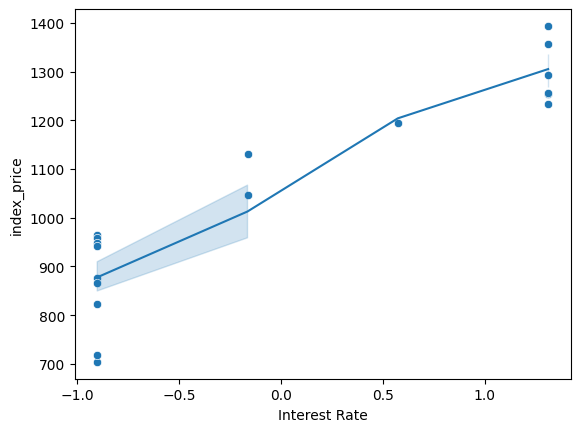

In [43]:
sns.scatterplot(x=X_train[:,0],y=y_train)
sns.lineplot(x=X_train[:,0],y=regression.predict(X_train))
plt.xlabel("Interest Rate")
plt.show()

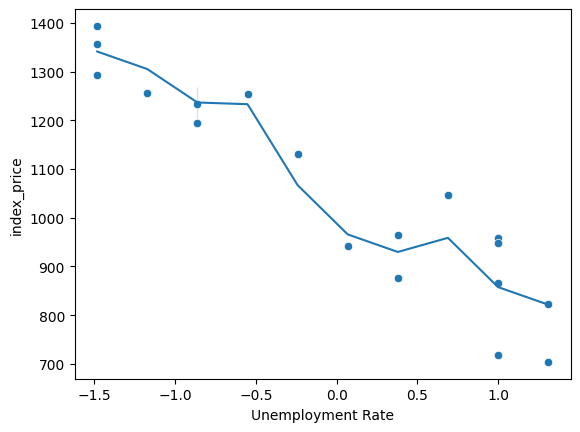

In [44]:
sns.scatterplot(x=X_train[:,1],y=y_train)
sns.lineplot(x=X_train[:,1],y=regression.predict(X_train))
plt.xlabel("Unemployment Rate")
plt.show()

In [45]:
# It will be 3D diagram if want to check plot the best fit line for 2 indepedent features and 1 dependent features

In [ ]:
from sklearn.model_selection import cross_val_score
# Check scoring parameter for more methods of validation score
cv_score=cross_val_score(regression,X_train,y_train,scoring="neg_mean_squared_error",cv=3)
cv_score

array([-4921.61331265, -7686.87497294, -5135.9962549 ])

In [48]:
cv_score.mean()

np.float64(-5914.828180162386)

In [49]:
# Prediction
y_pred=regression.predict(X_test)
y_pred

array([1204.22770398,  821.65051903, 1406.51300368,  857.70889608,
        994.90992298, 1168.16932693])

In [50]:
# Performance Metrics
from sklearn.metrics import mean_squared_error,mean_absolute_error,root_mean_squared_error,r2_score
print(mean_squared_error(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))
print(root_mean_squared_error(y_test,y_pred))

5793.762887712569
59.935781523235484
76.11677139574805


In [51]:
r2=r2_score(y_test,y_pred)
r2

0.8278978091457145

In [54]:
adjusted_r2=1-((1-r2)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1))

In [55]:
adjusted_r2

0.7131630152428576

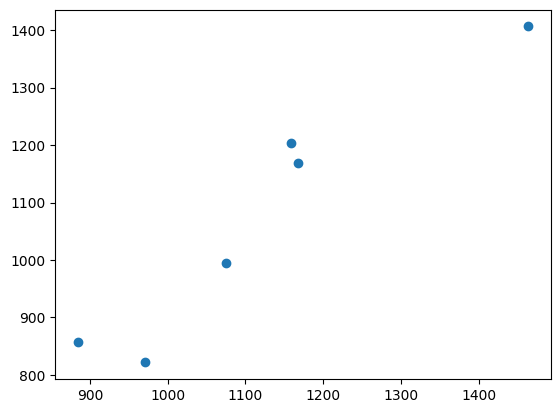

In [57]:
## Assumptions - How model is performing
plt.scatter(y_test,y_pred)
# If there is a linear relationship that means the model has performed well

In [58]:
residuals=y_test-y_pred
print(residuals)

8     -45.227704
16    149.349481
0      57.486996
18     26.291104
11     80.090077
9      -1.169327
Name: index_price, dtype: float64


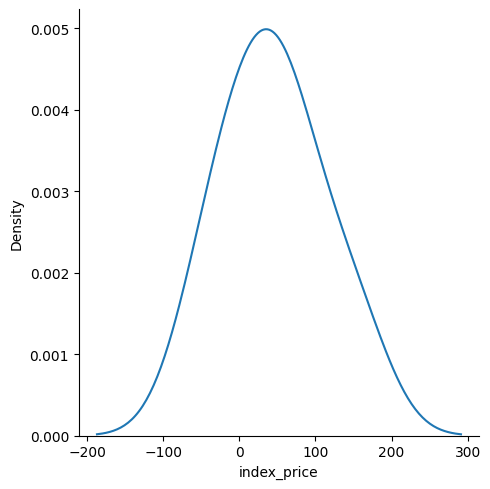

In [ ]:
# Plot the residuals distribution plot
sns.displot(residuals,kind="kde")
# if it is normal distribution then the model created is good and normal

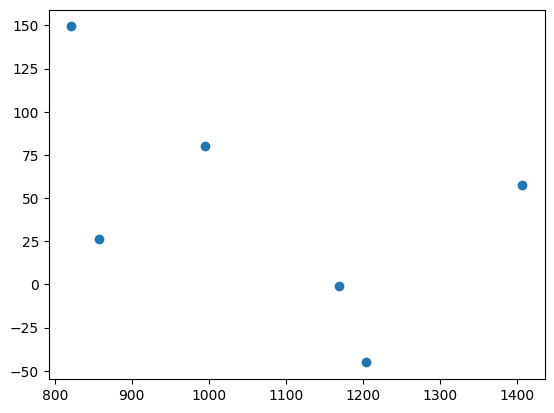

In [ ]:
# Scatter plot with respect to predictions and residuals
plt.scatter(y_pred,residuals)
# It should be uniformly distributed (the residuals should be nearby and osscilating near a uniform value)

In [67]:
X_train.reshape(-1,2)

array([[-0.90115511,  0.37908503],
       [ 1.31077107, -1.48187786],
       [-0.90115511,  1.30956648],
       [ 1.31077107, -0.55139641],
       [ 1.31077107, -1.48187786],
       [-0.16384638,  0.68924552],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -1.48187786],
       [ 1.31077107, -1.17171738],
       [-0.90115511,  1.30956648],
       [-0.90115511,  0.999406  ],
       [-0.90115511,  0.37908503],
       [-0.90115511,  0.999406  ],
       [ 0.57346234, -0.8615569 ],
       [-0.16384638, -0.24123593],
       [-0.90115511,  0.06892455],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -0.8615569 ]])

In [72]:
y_train=y_train.values.reshape(-1,1)

In [74]:
# Calculating the OLS (Ordinary Least Square)
# (XTX)B=(XTY)

In [75]:
import statsmodels.api as sm
model=sm.OLS(y_train,X_train).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.035
Model:                            OLS   Adj. R-squared (uncentered):             -0.086
Method:                 Least Squares   F-statistic:                             0.2880
Date:                Wed, 27 May 2026   Prob (F-statistic):                       0.754
Time:                        16:43:03   Log-Likelihood:                         -150.85
No. Observations:                  18   AIC:                                      305.7
Df Residuals:                      16   BIC:                                      307.5
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            88.2728    658.295      0.134      0.895   -1307.250    1483.796
x2          -116.2572    658.295     -0.177      0.862   -1511.780    1279.266
==============================================================================
Omnibus:                        0.598   Durbin-Watson:                   0.007
Prob(Omnibus):                  0.741   Jarque-Bera (JB):                0.567
Skew:                          -0.361   Prob(JB):                        0.753
Kurtosis:                       2.517   Cond. No.                         4.78
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [76]:
regression.coef_,regression.intercept_

(array([  88.27275507, -116.25716066]), np.float64(1053.4444444444443))

In [ ]:
## What will happen if independent feature are correlated by 90% or more
# Both the feature are same, so we can remove one of the feature
# We will see this in our next project